# Inverse Problems 2026 - Exercise 3 (home exercises)

Return by **Fri 20.11.2026 at 23:59** in Moodle! You can ask for help with these exercises in the exercise session the same day (10:00, room 7334).

The returned exercises should be renamed `Exercise03_lastname_firstname.ipynb` and contain your solutions in clear and readable manner and format. The programming exercises need to be runnable with minimal effort. If you find markdown too cumbersome for writing the necessary math, you can attach **a single extra pdf-file** for the theoretical exercises and denote it `Exercise03_lastname_firstname.pdf`.

___
In the following exercises you should use the given function `create_sinogram(N, angles)` to create the simulated tomography data, formulated as sinogram.
You can create the forward operator as matrix `A` using the function `create_radon_matrix(N, n_det, angles, sparse=False)`.
___

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize
import astra

def create_sinogram(N, angles = np.arange(360)):
    """Simple data generation function. Given the resolution `N` (for N x N images),
    creates the famous Shepp-Logan phantom at TWICE the spatial resolution, then projects
    it to noise-free sinogram using the given projection `angles` (in degrees) to avoid
    inverse crime.
    Shepp-Logan phantom of size N x N is also returned
    
    If `angles` are not specified, use 360 projections at 0 degree interval [0, 1, ..., 359].
    """
    n_det = 2*np.ceil(np.sqrt(2)*N).astype(int)
    anglesRad = np.deg2rad(angles)

    projGeom = astra.create_proj_geom('parallel', 0.5, n_det, anglesRad)
    volGeom = astra.create_vol_geom(N,N)
    projId = astra.create_projector("strip", projGeom, volGeom)

    volId, phantom_big = astra.data2d.shepp_logan(volGeom, modified=True)
    phantom = resize(phantom_big, output_shape=(N, N))

    # Calculate forward projection
    projection_id = astra.data2d.create('-sino', projGeom)
    cfg = astra.astra_dict('FP')
    cfg['ProjectorId'] = projId
    cfg['ProjectionDataId'] = projection_id
    cfg['VolumeDataId'] = volId
    algorithm_id = astra.algorithm.create(cfg)

    astra.algorithm.run(algorithm_id)

    sino_big = astra.data2d.get(projection_id)

    # Bin along detector positions -> detector width halves
    sino = 0.5*(sino_big[:, 0:-2:2] + sino_big[:, 1:-1:2]) / N
    return sino, phantom

def create_radon_matrix(N, n_det, angles):
    """Helper function to create the forward operator as a matrix using the
    ASTRA-toolbox.
    
    N is the target resolution, i.e. it is assumed to be N x N image dropped to vector along
    rows (C-format, default behaviour in Numpy).
    n_det is the number of detector elements or rows in the sinogram.
    """
    anglesRad = np.deg2rad(angles)
    projGeom = astra.create_proj_geom('parallel', 1.0, n_det, anglesRad)
    volGeom = astra.create_vol_geom(N,N)
    projId = astra.create_projector("strip", projGeom, volGeom)
    matrixId = astra.projector.matrix(projId)
    astra.projector.delete(projId) # Free memory
    A = astra.matrix.get(matrixId)
    return A / N

N = 64
n_ang = 360
m, x_true = create_sinogram(N, np.arange(n_ang))
n_ang, n_det = m.shape

A = create_radon_matrix(N, n_det, np.arange(n_ang))
m_crime = (A @ x_true.reshape((-1,1))). reshape((n_ang, n_det))
bp = (A.T @ m.reshape((-1,1))).reshape((N,N))

fig = plt.figure(figsize=(8,5))

ax2 = fig.add_subplot(2,1,2)
im2 = ax2.imshow(m.T, aspect=2)
fig.colorbar(im2)
ax2.set_title("Sinogram");

ax1 = fig.add_subplot(2,2,1)
im1 = ax1.imshow(x_true)
fig.colorbar(im1)
ax1.set_title("Shepp-Logan phantom");

ax3 = fig.add_subplot(2,2,2)
im3 = ax3.imshow(bp)
fig.colorbar(im3)
ax3.set_title("Naive backprojection");

ModuleNotFoundError: No module named 'astra'

## Task 1 (Filtered backprojection)
Theorem 3.3 of the lecture notes gives the analytic Radon inversion formula which is also the basis for the industry standard Filtered Backprojection algorithm (FBP):
$$ f = \frac{1}{4\pi} \mathcal{R}^* \mathcal{I}^{-1} \mathcal{R} f. $$
$\mathcal{R} f$ is the measured data, the adjoint of Radon transform $\mathcal{R}^*$ is the backprojection and the filtering means the inverse Ries potential which is a specific Fourier domain multiplier.

1.) Let's implement FBP ourselves. Below you can find partial code. Finish the implementation of the inverse Riesz potential and apply `FBP` to given sinogram data. Note that the sinogram should not be dropped to a vector!  
2.) Test our implementation of FBP on data with noise levels $\sigma = 0, 0.01$ and $0.05$. What do you see?  
3.) Here the Fourier multiplier or filter is defined as $h_1(s) = |s|$, which is in theory the correct choice. It is also known as the "ramp" filter. In practice [other similar filters](https://scikit-image.org/docs/stable/auto_examples/transform/plot_radon_transform.html#reconstruction-with-the-filtered-back-projection-fbp) are used. Implement and test the Shepp-Logan filter $h_2(s) = |s| \tfrac{\sin(0.5 \pi s)}{0.5 \pi s} = h_1(s) \tfrac{\sin(0.5 \pi s)}{0.5 \pi s}$, proposed by [Larry Shepp and Benjamin Logan in 1974](https://web.archive.org/web/20160304035526/http://stat.wharton.upenn.edu/~shepp/publications/33.pdf) again using the noise levels $\sigma = 0, 0.01$ and $0.05$. What do you see and why? 

_Note: Getting the scale of the reconstructed values correct is difficult but you do not have to worry about that here._

In [2]:
from scipy.fft import fft, ifft, fftfreq, fftshift
rng = np.random.default_rng(42)

def ramp(s):
    """Inverse Riesz multiplier h(s) = |s| at the FFT frequency bins."""
    return np.abs(s)

def shepp_logan(s):
    """Ramp multiplied by sinc(s/2) = sin(pi*s/2)/(pi*s/2)."""
    # np.sinc(0) = 1, so the zero-frequency value is handled without division.
    return np.abs(s) * np.sinc(s / 2)

def FBP(sinogram, N, BP_mtx, filter=ramp):
    """Filter each projection along its detector axis, then backproject."""
    n_ang, n_det = sinogram.shape
    if BP_mtx.shape != (N * N, n_ang * n_det):
        raise ValueError("Backprojection matrix and sinogram dimensions do not match")

    # Step 1: Transform along detector positions, not projection angles.
    freq_data = fft(sinogram, axis=1)

    # Step 2: Apply the inverse Riesz multiplier at the FFT bins.
    # fftfreq lies in [-0.5, 0.5) cycles/sample; keep the assignment's scaling.
    freqs = fftfreq(n_det).reshape((1, -1))
    freq_data *= filter(freqs)
    freq_data *= n_det**2 / n_ang  # Provided discrete scaling convention.

    # Step 3: Return to detector space; numerical imaginary roundoff is discarded.
    sino_data = ifft(freq_data, axis=1).real

    # Step 4: A.T is the discrete backprojection; only now flatten the sinogram.
    recn = BP_mtx @ sino_data.reshape(-1)
    return np.asarray(recn).reshape((N, N))


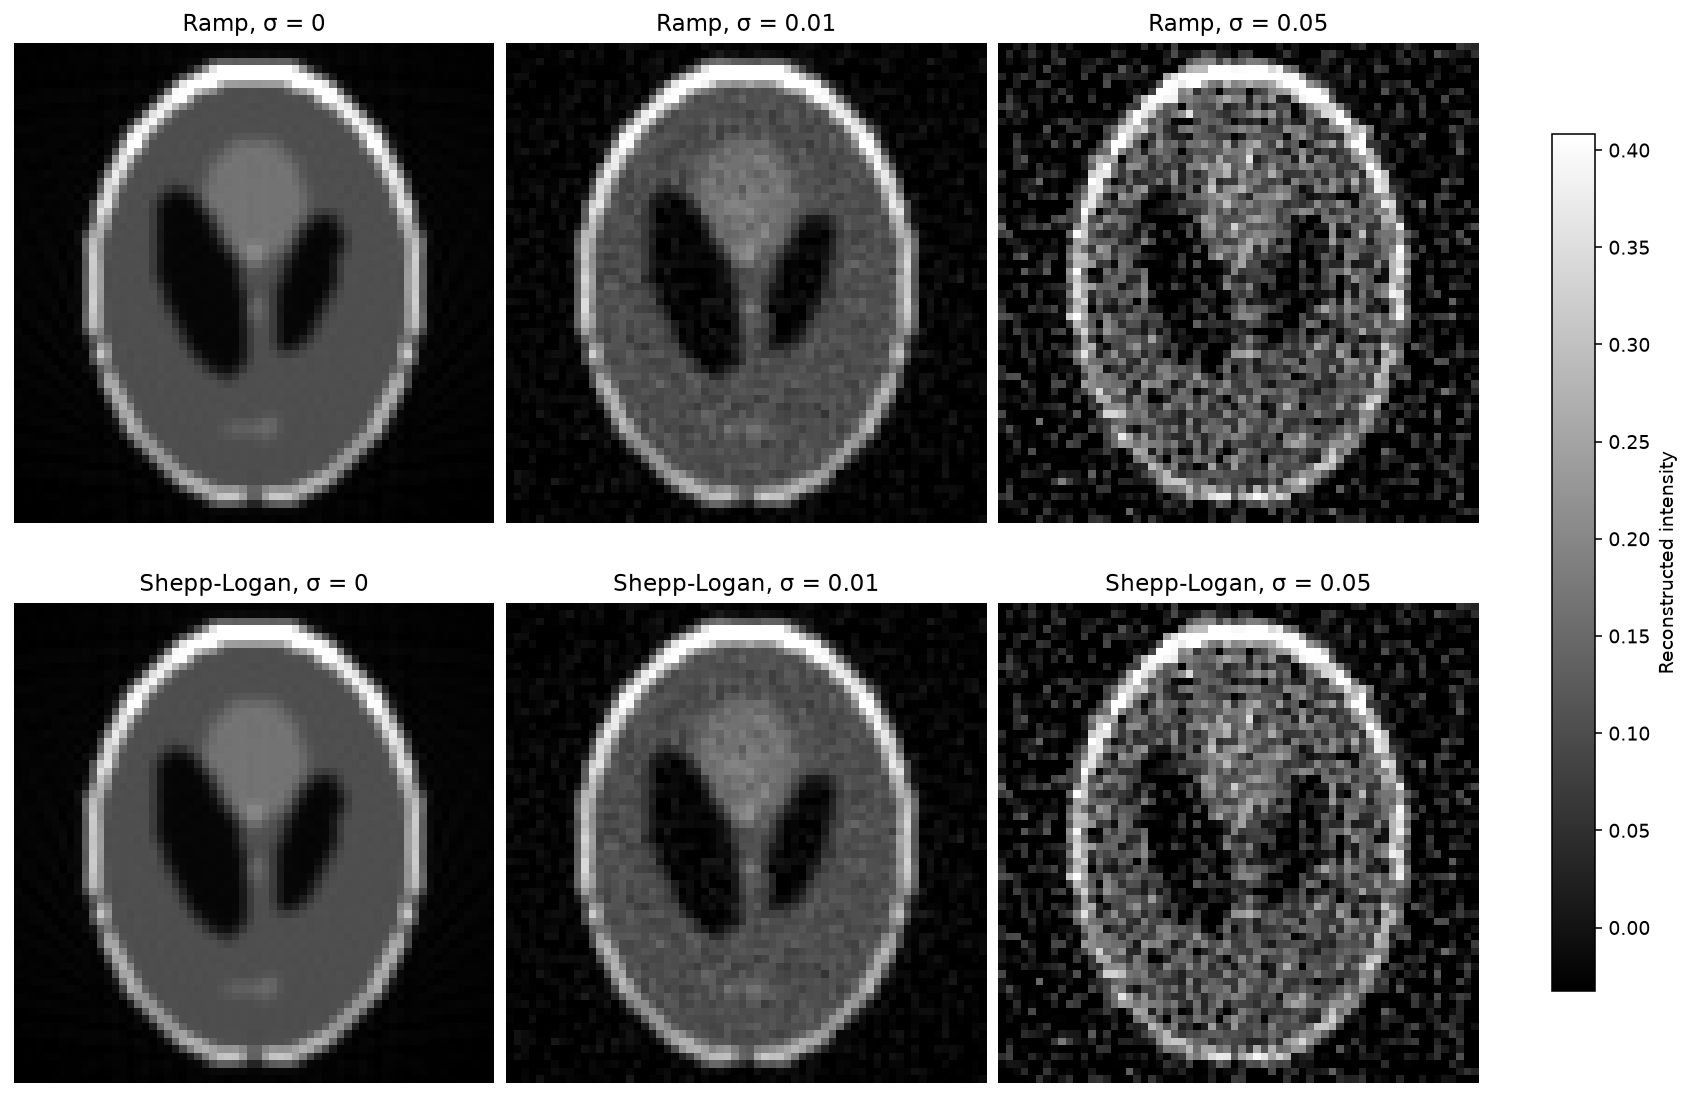

Scale-adjusted relative error against supplied phantom:
  Ramp         σ=0.00: 0.4487
  Ramp         σ=0.01: 0.4592
  Ramp         σ=0.05: 0.6359
  Shepp-Logan  σ=0.00: 0.4521
  Shepp-Logan  σ=0.01: 0.4615
  Shepp-Logan  σ=0.05: 0.6259


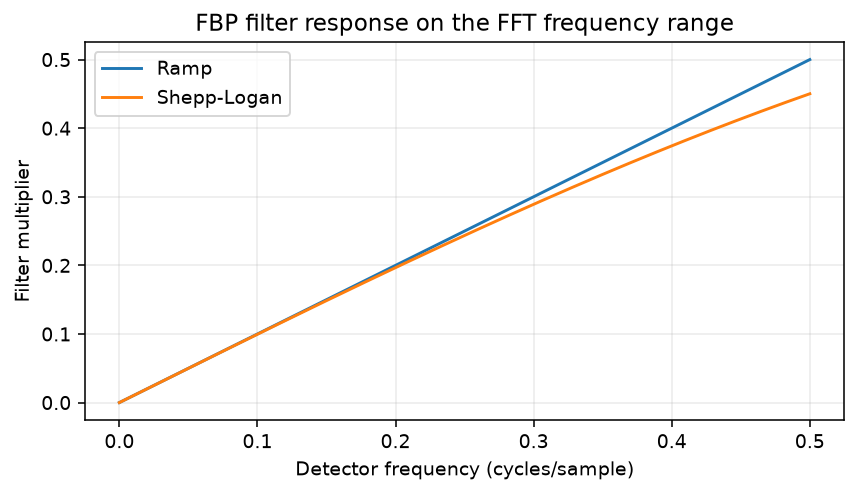

In [3]:
# Step 1: Use one reproducible noise realization per level for both filters.
noise_levels = (0, 0.01, 0.05)
noisy_sinograms = {
    sigma: m + sigma * rng.standard_normal(m.shape) for sigma in noise_levels
}

# Step 2: Reconstruct with the discrete adjoint of the supplied Radon matrix.
filters = {"Ramp": ramp, "Shepp-Logan": shepp_logan}
reconstructions = {
    (name, sigma): FBP(noisy_sinograms[sigma], N, A.T, multiplier)
    for name, multiplier in filters.items()
    for sigma in noise_levels
}

# Step 3: Use identical display limits so noise and filter differences are comparable.
clean_ramp = reconstructions["Ramp", 0]
vmin, vmax = np.percentile(clean_ramp, (1, 99))
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for row, name in enumerate(filters):
    for col, sigma in enumerate(noise_levels):
        image = reconstructions[name, sigma]
        im = axes[row, col].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
        axes[row, col].set_title(f"{name}, σ = {sigma:g}")
        axes[row, col].axis("off")
fig.colorbar(im, ax=axes, shrink=0.78, label="Reconstructed intensity")
plt.show()

# Step 4: Compare spatial error after fitting one display-scale factor.
# The assignment explicitly allows a global scale mismatch; fitting it is for
# evaluation only and does not alter any reconstruction or plotted image.
print("Scale-adjusted relative error against supplied phantom:")
for name in filters:
    for sigma in noise_levels:
        image = reconstructions[name, sigma]
        gain = np.vdot(image, x_true) / np.vdot(image, image)
        relative_error = np.linalg.norm(gain * image - x_true) / np.linalg.norm(x_true)
        print(f"  {name:12s} σ={sigma:4.2f}: {relative_error:.4f}")

# The two Fourier multipliers clarify the expected noise behavior.
frequency = np.linspace(0, 0.5, 300)
plt.figure(figsize=(7, 3.5))
plt.plot(frequency, ramp(frequency), label="Ramp")
plt.plot(frequency, shepp_logan(frequency), label="Shepp-Logan")
plt.xlabel("Detector frequency (cycles/sample)")
plt.ylabel("Filter multiplier")
plt.title("FBP filter response on the FFT frequency range")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


### Task 1: results and interpretation

The unfiltered backprojection in the setup cell spreads each detector value across image lines and is visibly blurred. FBP filters each projection **along its detector axis** with the inverse Riesz multiplier before backprojecting with `A.T` (lecture notes, Theorem 3.3, p. 17). The sinogram stays two-dimensional until the matrix multiplication.

The executed comparison uses the **same noise realization for both filters** at each level and the **same grayscale limits for all six images**. At $\sigma=0$, both reconstructions recover the main phantom structures and are much sharper than naive backprojection, though the small features and edges differ from the supplied phantom. At $\sigma=0.01$, faint grain and streaks appear. At $\sigma=0.05$, noise visibly obscures parts of the interior. The ramp accentuates this because its multiplier $|s|$ gives more weight to high-frequency components, including high-frequency measurement noise.

| Filter | $\sigma=0$ | $\sigma=0.01$ | $\sigma=0.05$ |
|---|---:|---:|---:|
| Ramp | 0.4487 | 0.4592 | 0.6359 |
| Shepp–Logan | 0.4521 | 0.4615 | 0.6259 |

These are **scale-adjusted relative image errors**, computed only for comparison because the assignment does not require exact intensity scaling. Ramp has slightly lower error for noiseless and low-noise data; Shepp–Logan is slightly better at $\sigma=0.05$. The displayed Shepp–Logan images look a little smoother, with a small loss of edge sharpness. This matches its multiplier $|s|\,\mathrm{sinc}(s/2)$, which tapers high frequencies. `fftfreq(n_det)` spans $[-0.5,0.5)$ cycles/sample, so the specified taper is mild on the actual grid; the filter-response plot confirms why the two rows are visually similar. At zero frequency, `np.sinc(0)=1` avoids division by zero and the complete multiplier is zero for both filters. The remaining noiseless error also reflects finite detector resolution, discretization, and the deliberately different data-generation and reconstruction grids.


___
## Task 2 (Tikhonov regularization)
Using the given forward matrix `A` and noise-free data vector `m`, add normally distributed noise with standard deviation $\sigma = 0.02$ to it. Then solve the Tikhonov regularized solution for regularization parameters $\alpha = 0.01, 0.1$ and $1$ and plot the result.

___
## Task 3 (Iterative regularization)
Write a routine that implements the Landweber iterative method discussed in the lectures for $k = 2,7,25$ and $50$ iterations. Use $\beta = 1 / {\lambda^2_1}$ and some level of measurement noise. _Hint:_ For estimating $\lambda_1$, consider the [spectral norm](https://en.wikipedia.org/wiki/Matrix_norm#Spectral_norm_(p_=_2)) of $A$.

___
## Task 4 (TV denoising)
Total variation denoising (the Rudin–Osher–Fatemi model) finds
$$ f_\alpha = \operatorname{arg\,min}_f \left\lbrace \frac{1}{2} \| f - g^\delta \|^2 + \alpha \sum_{i,j} |(\nabla f)_{i,j}| \right\rbrace, $$
where $|(\nabla f)_{i,j}|$ is the Euclidean norm of the discrete gradient at pixel $(i,j)$. The objective is not differentiable where $\nabla f = 0$, so we replace $|\cdot|$ by the Huber function $\phi_\varepsilon$ (Exercise 2, Task 4). Gradient descent for the smoothed problem reads
$$ f^{k+1} = f^k + \tau \left( (g^\delta - f^k) - \alpha \nabla^T (w^k \nabla f^k) \right), \quad w^k_{i,j} = \frac{1}{\max \lbrace \varepsilon, |(\nabla f^k)_{i,j}| \rbrace}. $$

1. Implement the discrete gradient `grad` and its adjoint `grad_T` below. You should check that $\langle \nabla f, p \rangle = \langle f, \nabla^T p \rangle$ for random $f$ and $p$.
2. Implement the gradient descent and denoise the noisy image. Use $\varepsilon = 0.01$, step size $\tau = 1 / (1 + 8 \alpha / \varepsilon)$ and try a few values of $\alpha$.
3. Compare to the quadratic regularization $\frac{1}{2} \| f - g^\delta \|^2 + \frac{\alpha}{2} \| \nabla f \|^2$ (Tikhonov with $L = \nabla$). What happens to the edges?

In [ ]:
from skimage.data import shepp_logan_phantom
from skimage.transform import resize

rng = np.random.default_rng(3)
f_true = resize(shepp_logan_phantom(), (128, 128)) # Or use your own image from Exercise 1
g = f_true + 0.1 * rng.standard_normal(f_true.shape)

def grad(f):
    """Forward differences (h = 1) with zero difference at the last row/column (Neumann boundary).
    Returns an array of shape (2, N, M)."""
    ### TODO ###
    out = None
    return out

def grad_T(p):
    """Adjoint of `grad`, i.e. the negative (backward) divergence of the vector field p of shape (2, N, M)."""
    ### TODO ###
    out = None
    return out

plt.imshow(g, cmap="gray")
plt.title("Noisy image");